

```
# 此內容會顯示為程式碼
```

# CellAtlas Colab demo

This notebook follows: TIFF slices → 3D volumes (niigz. format) → PKL. format → membrane prediction → instance cell segmentation → **m2nGAN** → morphology → GUI.

Upload `CellAtlasDemo.zip` to My Drive, select a **T4 GPU**, and run the cells in order. The official example contains 10 time points for `200109plc1p1` and 8 for `200113plc1p2`, with 92 TIFF slices per frame.

The first setup creates a separate Python 3.12 environment. Cells beginning with `%%cellatlas` share that environment and variables; Colab's preinstalled packages are not changed. CD identities remain required. Sources are in `THIRD_PARTY.md`.

# (**Google Colab**)
# **1. 2D - > 3D Data Process Note**

## Build Your Training, Validating and Running Data to be Formatted Properly from 2D slices.

### We are grouping two wild-type embryo running data with max times 10 and 8 here for example. Training data and validating data could be composed at the same way.

### Upload `CellAtlasDemo.zip` to My Drive, then mount Drive below.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Extract the demo and install the fixed Python environment.

In [2]:
from pathlib import Path
import hashlib
import json
import os
import queue
import subprocess
import sys
import tempfile
import time
import zipfile

from IPython import get_ipython
from IPython.display import display
from jupyter_client import KernelManager
from jupyter_client.kernelspec import KernelSpecManager


ROOT = Path("/content/CellAtlasDemo")
ARCHIVE = Path("/content/drive/MyDrive/CellAtlasDemo.zip")
TOOLS = Path("/content/.cellatlas-tools")
PYTHON_ENV = Path("/content/.cellatlas-python")


def run_command(command):
    subprocess.run(command, check=True)


def mount_drive_if_needed():
    if ARCHIVE.is_file():
        return

    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as error:
        raise RuntimeError(
            f"Google Drive is not mounted and the archive was not found: {ARCHIVE}"
        ) from error

    if not ARCHIVE.is_file():
        raise FileNotFoundError(f"Archive not found: {ARCHIVE}")


def extract_and_verify_package():
    required_files = [
        ROOT / "PROVENANCE.json",
        ROOT / "colab_kernel.py",
        ROOT / "requirements-lock.txt",
    ]

    if not ROOT.exists():
        mount_drive_if_needed()

        with zipfile.ZipFile(ARCHIVE) as package:
            root_path = ROOT.resolve()

            for member in package.infolist():
                target = (Path("/content") / member.filename).resolve()
                if not target.is_relative_to(root_path):
                    raise ValueError(f"Unexpected archive path: {member.filename}")

            package.extractall("/content")

        print("Package extracted.")
    else:
        print("Package directory already exists. Skipping extraction.")

    missing = [str(path) for path in required_files if not path.is_file()]
    if missing:
        raise RuntimeError(
            "The package directory is incomplete. Missing files:\n"
            + "\n".join(missing)
        )

    manifest = json.loads((ROOT / "PROVENANCE.json").read_text())

    for relative_path, expected_hash in manifest["files"].items():
        file_path = ROOT / relative_path

        if not file_path.is_file():
            raise FileNotFoundError(f"Missing package file: {relative_path}")

        actual_hash = hashlib.sha256(file_path.read_bytes()).hexdigest()

        if actual_hash != expected_hash:
            raise ValueError(f"Package checksum mismatch: {relative_path}")

    print("Package verification passed.")


def prepare_python_environment():
    TOOLS.mkdir(parents=True, exist_ok=True)

    uv_path = TOOLS / "bin" / "uv"

    if not uv_path.is_file():
        run_command([
            sys.executable,
            "-m",
            "pip",
            "install",
            "--quiet",
            "--target",
            str(TOOLS),
            "uv==0.13.0",
        ])

    if not PYTHON_ENV.is_dir() or not (PYTHON_ENV / "bin" / "python").is_file():
        run_command([
            str(uv_path),
            "venv",
            "--python",
            "3.12.15",
            "--managed-python",
            str(PYTHON_ENV),
        ])

    isolated_python = PYTHON_ENV / "bin" / "python"

    run_command([
        str(uv_path),
        "pip",
        "install",
        "--python",
        str(isolated_python),
        "-r",
        str(ROOT / "requirements-lock.txt"),
    ])

    run_command([
        str(uv_path),
        "pip",
        "check",
        "--python",
        str(isolated_python),
    ])

    return isolated_python


def write_kernel_spec(isolated_python):
    kernel_root = TOOLS / "kernels"
    kernel_dir = kernel_root / "cellatlas"
    kernel_dir.mkdir(parents=True, exist_ok=True)

    kernel_spec = {
        "argv": [
            str(isolated_python),
            "-I",
            "-m",
            "ipykernel_launcher",
            "-f",
            "{connection_file}",
            "--IPKernelApp.kernel_class=ipykernel.ipkernel.IPythonKernel",
            "--IPKernelApp.extensions=[]",
        ],
        "display_name": "CellAtlas isolated Python",
        "language": "python",
        "env": {
            "MPLCONFIGDIR": str(TOOLS / "matplotlib"),
            "IPYTHONDIR": str(TOOLS / "ipython"),
            "JUPYTER_CONFIG_DIR": str(TOOLS / "jupyter"),
            "PYTHONNOUSERSITE": "1",
            "PYTHONPATH": "",
            "OMP_NUM_THREADS": "2",
            "OPENBLAS_NUM_THREADS": "2",
            "MPLBACKEND": "module://matplotlib_inline.backend_inline",
        },
    }

    (kernel_dir / "kernel.json").write_text(
        json.dumps(kernel_spec, indent=2)
    )


def start_cellatlas_kernel(isolated_python):
    shell = get_ipython()
    previous = shell.user_ns.get("_cellatlas_kernel")

    if previous is not None and previous[0].is_alive():
        print("CellAtlas kernel is already running.")
        return

    write_kernel_spec(isolated_python)

    kernel_log = ROOT / "kernel-startup.log"
    client = None

    manager = KernelManager(
        kernel_name="cellatlas",
        kernel_spec_manager=KernelSpecManager(
            kernel_dirs=[str(TOOLS / "kernels")]
        ),
    )

    environment = os.environ.copy()

    for variable in ("PYTHONHOME", "PYTHONPATH", "PYTHONSTARTUP"):
        environment.pop(variable, None)

    try:
        with kernel_log.open("w") as log_file:
            manager.start_kernel(
                cwd=str(ROOT),
                env=environment,
                stdout=log_file,
                stderr=subprocess.STDOUT,
            )

            client = manager.client()
            client.start_channels()
            client.wait_for_ready(timeout=120)

    except Exception:
        if client is not None:
            client.stop_channels()

        if manager.has_kernel:
            manager.shutdown_kernel(now=True)

        log_text = kernel_log.read_text(errors="replace")

        print("Kernel startup failed.")
        print("Startup log:")
        print(log_text or "<empty>")

        raise

    def run_cell(line, cell):
        if line.strip():
            raise ValueError("Use %%cellatlas without arguments.")

        message_id = client.execute(cell, stop_on_error=True)
        error = None
        last_message_time = time.monotonic()

        while True:
            try:
                message = client.get_iopub_msg(timeout=5)
            except queue.Empty:
                if not manager.is_alive():
                    raise RuntimeError(
                        "The CellAtlas kernel stopped during cell execution."
                    )

                if time.monotonic() - last_message_time > 30:
                    print("CellAtlas cell is still running...", flush=True)
                    last_message_time = time.monotonic()

                continue

            if message["parent_header"].get("msg_id") != message_id:
                continue

            message_type = message["header"]["msg_type"]
            content = message["content"]

            if message_type == "stream":
                print(content["text"], end="", flush=True)
                last_message_time = time.monotonic()

            elif message_type in ("display_data", "execute_result"):
                display(
                    content["data"],
                    raw=True,
                    metadata=content.get("metadata", {}),
                )

            elif message_type == "error":
                error = "\n".join(content["traceback"])

            elif (
                message_type == "status"
                and content["execution_state"] == "idle"
            ):
                break

        if error is not None:
            raise RuntimeError(error)

    shell.register_magic_function(
        run_cell,
        magic_kind="cell",
        magic_name="cellatlas",
    )

    shell.user_ns["_cellatlas_kernel"] = (manager, client)

    run_cell(
        "",
        """
import sys
import torch
import numpy
import scipy
import pandas
import open3d

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("NumPy:", numpy.__version__)

assert torch.cuda.is_available(), (
    "A GPU runtime is required. Enable GPU in Runtime > Change runtime type."
)

print("GPU:", torch.cuda.get_device_name(0))
""",
    )

    print("CellAtlas environment is ready.")
    print("Continue with the following %%cellatlas cells.")


extract_and_verify_package()
isolated_python = prepare_python_environment()
start_cellatlas_kernel(isolated_python)

Package extracted.
Package verification passed.
Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Python: 3.12.15 (main, Oct  9 2026, 15:22:32) [Clang 22.1.3 ]
PyTorch: 2.5.1+cu124
NumPy: 1.26.4
GPU: Tesla T4
CellAtlas environment is ready.
Continue with the following %%cellatlas cells.


### Generate the name_dictionary.csv and number_dictionary.csv for your new cd file and embryos.

In [3]:
%%cellatlas
import sys
print(sys.version)


3.12.15 (main, Oct  9 2026, 15:22:32) [Clang 22.1.3 ]


In [4]:
%%cellatlas


import glob
import os
from data.generate_number_dictionary import add_number_dict


CD_folder = r"./dataset/run/CDFiles"
nuc_files = sorted(glob.glob(os.path.join(CD_folder, "*.csv")))

for idx, nuc_file in enumerate(nuc_files): # go through all cd files, one cd file for one embryo
    add_number_dict(nuc_file, max_time=1000) # the max time for your data

Old name list length: 4058 New name list length 3916
Updated cells: []
Old name list length: 4058 New name list length 1430
Updated cells: []


### Compose the 2D raw membrane channel tiff images into 3D niigz volumes.

In [5]:
%%cellatlas
# !!!!!Please buy colab pro if you need to deal with the real problems!!!!! Colab Pro allow you to hold the connection for a long time! But free colab not.
# configuration
config = dict(num_slice=92, # the depth, the z axia, how many slices along z
                  embryo_names=['200109plc1p1','200113plc1p2'], # you can give a list if you have many embryos, remember to group them under ./dataset/run/{embryo name}
                  max_times = [10,8], # the max time, should match the embryo.
                  xy_resolution = 0.09,
                  z_resolution = 0.42,
                  # the z dimension is calculated by: 92  *   0.42/0.09  *  356/712; (2d height / 3d height)
                  out_size = [256, 356, 214], # todo: need to be calculated with the vertical image amount
                  raw_folder=r'./dataset/run/',
                  target_folder=r"./dataset/run/",
                  save_nuc = False, # group the nucleus channel images to 3d niigz file
                  save_memb = True, # group the membrane channel images to 3d niigz file
                  lineage_file = True,# group the cell position from cd file in to niigz for seeded watershed instance segmentation
                  name_dictionary = r"./dataset/name_dictionary.csv"
                  )


num_slice = config["num_slice"]
embryo_names = config["embryo_names"]
max_times = config["max_times"]
xy_res = config["xy_resolution"]
z_res = config["z_resolution"]
out_size = config["out_size"]
raw_folder = config["raw_folder"]
stack_folder = config["target_folder"]
is_save_nuc_channel = config["save_nuc"]
is_save_memb_channel = config["save_memb"]
is_save_seg_cell_with_cd_file=config["lineage_file"]
name_dictionary_path=config['name_dictionary']

In [6]:
%%cellatlas
from reference_support import check_tiffs
check_tiffs(embryo_names, max_times, config['num_slice'])
from PIL import Image
import numpy as np
import multiprocessing as mp


# preparation before composing images

# get output size
raw_memb_files = glob.glob(os.path.join(raw_folder, embryo_names[0], "tifR", "*.tif"))
print('length of the raw membrane/nucleus slices', len(raw_memb_files))
raw_size = list(np.asarray(Image.open(raw_memb_files[0])).shape) + [int(num_slice * z_res / xy_res)]
out_res = [res * in_scale / out_scale for res, in_scale, out_scale in zip([xy_res, xy_res, xy_res], raw_size, out_size)]
print('composing output shape resolution',out_res)

# multiprocessing
mpPool = mp.Pool(1)

TIFF input checks: [{'embryo': '200109plc1p1', 'timepoints': 10, 'slices': 920}, {'embryo': '200113plc1p2', 'timepoints': 8, 'slices': 736}]
length of the raw membrane/nucleus slices 920
composing output shape resolution [0.18, 0.18, 0.18042056074766355]



### Compose the membrane and nucleus 2D slices; generate the segNuc according to CD{embryo name}.csv file.

In [7]:
%%cellatlas
from tqdm import tqdm
import pandas as pd

from data.preprocess_utils import save_nuc_seg,stack_memb_slices,stack_nuc_slices
from data.data_structure import read_cd_file

for idx_embryo,embryo_name in enumerate(embryo_names):

    # get lineage file successfully?
    if is_save_seg_cell_with_cd_file:
        lineage_file_path = os.path.join(raw_folder, 'CDFiles', "CD{}.csv".format(embryo_name))
    else:
        lineage_file_path = None

    # ------------------Not provided here--- save nucleus-------------------------
    if is_save_nuc_channel:
        origin_folder = os.path.join(raw_folder, embryo_name, "tif")
        target_folder = os.path.join(stack_folder, embryo_name, "RawNuc")
        if not os.path.isdir(target_folder):
            os.makedirs(target_folder)

        configs = []
        for tp in range(1, max_times[idx_embryo] + 1):
            configs.append((origin_folder, target_folder, embryo_name, tp, out_size, num_slice, out_res))

        for idx, _ in enumerate(tqdm(mpPool.imap_unordered(stack_nuc_slices, configs), total=len(configs),
                                     desc="Stacking nucleus of {}".format(embryo_name))):
            pass

    # ---------------------- save membrane --------------------------
    if is_save_memb_channel:
        origin_folder = os.path.join(raw_folder, embryo_name, "tifR")
        target_folder = os.path.join(stack_folder, embryo_name, "RawMemb")
        if not os.path.isdir(target_folder):
            os.makedirs(target_folder)

        configs = []
        for tp in range(1, max_times[idx_embryo] + 1):
            configs.append((origin_folder, target_folder, embryo_name, tp, out_size, num_slice, out_res))
            # stack_memb_slices(configs[0])
        for idx, _ in enumerate(tqdm(mpPool.imap_unordered(stack_memb_slices, configs), total=len(configs),
                                     desc="Stacking membrane of {}".format(embryo_name))):
            pass

    # save nucleus
    if is_save_seg_cell_with_cd_file:
        assert lineage_file_path is not None
        target_folder = os.path.join(stack_folder, embryo_name, "SegNuc")
        if not os.path.isdir(target_folder):
            os.makedirs(target_folder)
        pd_lineage = read_cd_file(lineage_file_path)

        label_name_dict = pd.read_csv(name_dictionary_path, index_col=0).to_dict()['0']
        name_label_dict = {value: key for key, value in label_name_dict.items()}

        configs = []
        for tp in range(1, max_times[idx_embryo] + 1):
            configs.append((embryo_name, name_label_dict, pd_lineage, tp, raw_size, out_size, out_res,
                            xy_res / z_res, target_folder))
            # save_nuc_seg(configs[0])
        for idx, _ in enumerate(tqdm(mpPool.imap_unordered(save_nuc_seg, configs), total=len(configs),
                                     desc="Constructing segNuc(nucleus location) of {}".format(embryo_name))):
            # TODO: Process Name: `3/3 Construct nucleus location`; Current status: `idx`; Final status: max_time
            pass
#         shutil.copy(lineage_file_path, os.path.join(stack_folder, embryo_name))
mpPool.close()
mpPool.join()


Stacking membrane of 200109plc1p1: 100%|██████████| 10/10 [00:44<00:00,  4.46s/it]
Constructing segNuc(nucleus location) of 200109plc1p1: 100%|██████████| 10/10 [00:04<00:00,  2.03it/s]
Stacking membrane of 200113plc1p2: 100%|██████████| 8/8 [00:31<00:00,  3.94s/it]
Constructing segNuc(nucleus location) of 200113plc1p2: 100%|██████████| 8/8 [00:02<00:00,  3.39it/s]


The 2D raw image (xy panel) resolution is x, y:  [512, 712]
The 3D composed volume resolution is x, y, z:  [256, 356, 214]
The middle horizontal view (xy panel)


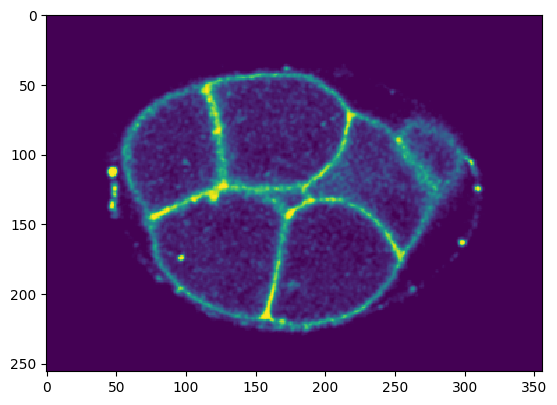

The middle segittal view (yz panel)


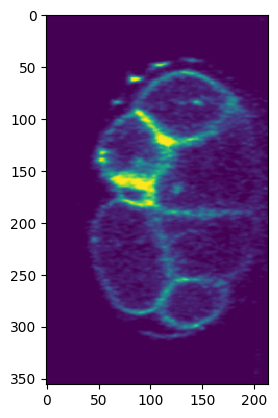

The middle coronal view (xz panel)


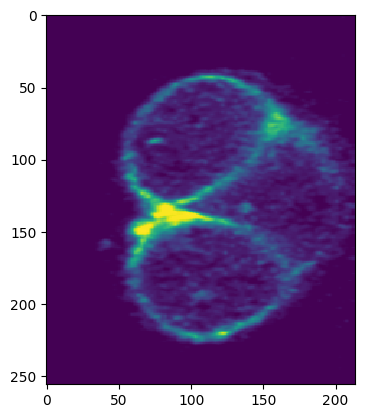

In [8]:
%%cellatlas
%matplotlib inline
from matplotlib import pyplot as plt
from utils.data_io import nib_load

print('The 2D raw image (xy panel) resolution is x, y: ', raw_size[:2])
print('The 3D composed volume resolution is x, y, z: ', out_size)

showing_data=nib_load(r'./dataset/run/200109plc1p1/RawMemb/200109plc1p1_010_rawMemb.nii.gz')

print('The middle horizontal view (xy panel)')
plt.imshow(showing_data[:,:,out_size[2]//2], interpolation='nearest')
plt.show()

print('The middle segittal view (yz panel)')
plt.imshow(showing_data[out_size[0]//2,:,:], interpolation='nearest')
plt.show()

print('The middle coronal view (xz panel)')
plt.imshow(showing_data[:,out_size[1]//2,:], interpolation='nearest')
plt.show()


## RawMemb volumes and CD-derived SegNuc points are ready. This membrane-only example has no acquired RawNuc channel.

## Transform the niigz to pkl for quick loading into memory (you MUST run this block to get pickle file to run segmentation part).

In [9]:
%%cellatlas
from data.preprocess import niigz_to_pkl_run

running_folder = dict(root="dataset/run", has_membrane_label=False,has_nucleus_label=True)

# nii.gz to pickle, make it easier to read in neural network
niigz_to_pkl_run(running_folder, embryo_names=embryo_names, max_times=max_times)

savingdataset/run/200113plc1p2: 100%|██████████| 8/8 [00:12<00:00,  1.58s/it]


# **2. Due to the online computation resource, training not show on colab. If you have your own training data, please run them on a your computer with at least a 2080Ti with 12GB (or better gpu)**

# **3. Run the segmentation on your time-lapse 3D embryos data!\**

## Place your runing augments at the Paramenters configuration section and ./experiment/TRAIN_TEST.yaml (if you are running segmentation on your own embryos/fluorescent images).

In [10]:
%%cellatlas
# !pip install setproctitle

In [11]:
%%cellatlas

import os
import time
import logging
import random
import argparse
# import setproctitle
import numpy as np

import torch
import torch.backends.cudnn as cudnn
from torch.utils.data import DataLoader

import models
from utils import ParserUse


In [12]:
%%cellatlas
cudnn.benchmark = True
## parse arguments
args = ParserUse('TRAIN_TEST', log='run')
# CHANGE Your training parameters here below
args.running_folder=r'./dataset/run'
# change your embryo names and their max times here!
# We just present two embryos, with 10 and 8 frame respectively for demonstration.
# But remember to buy more system RAW and colab pro to ensure your computation is stable.
args.running_embryos=['200109plc1p1','200113plc1p2']
args.run_max_times=[10,8]
args.mode=2
args.gpu='0'
args.ckpts='./ckpts'
args.suffix='*.pkl'
args.save_format='nii'
args.resume=r'./ckpts/CTransformer_model_epoch_50.pth'
is_scoring = False

In [13]:
%%cellatlas
# CUDA_VISIBLE_DEVICES is inherited from the runtime.
assert torch.cuda.is_available(), "GPU is needed for prediction"

# =============================================================
#  set seeds for randomlization in TRAIN_TEST.yaml
# =============================================================
torch.manual_seed(args.seed)
torch.cuda.manual_seed(args.seed)
random.seed(args.seed)
np.random.seed(args.seed)
torch.set_num_threads(2)
cudnn.benchmark = False


In [14]:
%%cellatlas
import open3d
print('Open3D:', open3d.__version__)


Open3D: 0.19.0


## Start run the cell membrane prediction on the current colab computer with gpu (free T4).

In [15]:
%%cellatlas
torch.cuda.reset_peak_memory_stats()


import shutil


from data import datasets
from utils.prediction_utils import validate

# start to predict the unconstant eggshell (prediciton, binary segmentation)
if args.get_memb_bin:
    # get membrane binary shell
    # nii.gz to pickle, make it easier to read in neural network
    # doit(test_folder, embryo_names=args.test_embryos, max_times=args.max_times)
    # =============================================================
    #  construct network model
    # =============================================================
    Network = getattr(models, args.net)
    model = Network(**args.net_params)
    model = torch.nn.DataParallel(model).cuda()
    print("="*20 + "Loading parameters {}".format(args.resume) + "="*20)
    assert os.path.isfile(args.resume), "{} ".format(args.resume) + "doesn't exist"
    check_point = torch.load(args.resume, map_location='cpu', weights_only=False)
    args.start_iter = check_point["iter"]
    model.load_state_dict(check_point["state_dict"])

    msg = ("Loaded checkpoint '{}' (iter {})".format(args.resume, check_point["iter"]))
    msg = msg + "\n" + str(args)

#     logging.info(msg)

    root_path=args.running_data_dir

    if args.get_memb_bin or args.get_cell:
        if args.running_embryos is None:
            args.running_embryos = [name for name in os.listdir(root_path) if os.path.isdir(os.path.join(root_path, name))]
    Dataset = getattr(datasets, args.dataset)
    test_set = Dataset(root=root_path, membrane_names=args.running_embryos, for_train=False, transforms=args.test_transforms,
                       return_target=is_scoring, suffix=args.suffix, max_times=args.run_max_times)
    test_loader = DataLoader(
        dataset=test_set,
        batch_size=1,
        shuffle=False,
        # collate_fn=test_set.collate, # control how data is stacked
        num_workers=0, # enlarge the number if you have buy colab pro with large system RAM
        pin_memory=True
    )

    #=============================================================
    #  begin prediction
    #=============================================================
    output_saving_path=r'./dataset/run'

    # the edt cell membrane file will save in the {savepath}/{embryo_name}/segMemb folder
    with torch.no_grad():
        validate(
            valid_loader=test_loader,  # dataset loader
            model=model,  # model
            savepath=output_saving_path,  # output folder
            names=test_set.names,  # stack name lists
            scoring=False,  # whether keep accuracy
            save_format=".nii.gz",  # save volume format
            snapsot=None,  # whether keep snap
            postprocess=False,
            size=test_set.size
        )
from pathlib import Path
import gc, json
Path("reports/membrane_memory.json").write_text(json.dumps({
    "peak_allocated_bytes": torch.cuda.max_memory_allocated(),
    "peak_reserved_bytes": torch.cuda.max_memory_reserved(),
    "device": torch.cuda.get_device_name(0)
}, indent=2))
del model, check_point, test_loader, test_set
gc.collect()
torch.cuda.empty_cache()


====================Loading parameters ./ckpts/CTransformer_model_epoch_50.pth====================
Getting binary membrane:: 100%|██████████| 18/18 [03:23<00:00, 11.31s/it]


The middle horizontal view (xy panel)


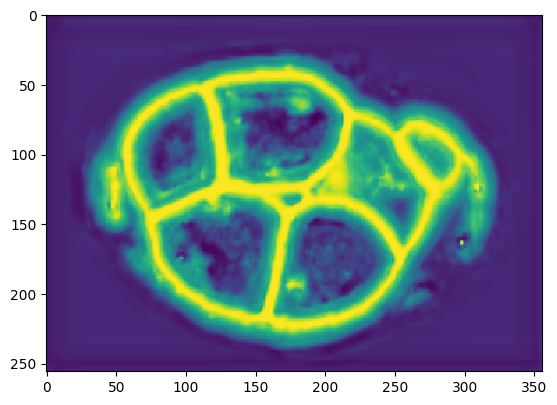

The middle segittal view (yz panel)


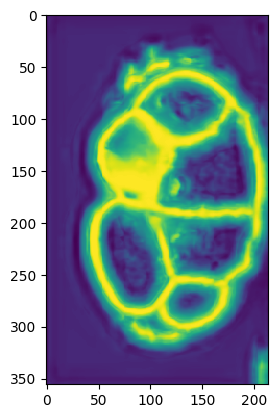

The middle coronal view (xz panel)


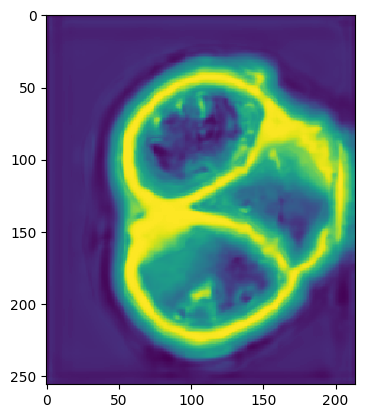

In [16]:
%%cellatlas
showing_data=nib_load(r'./dataset/run/200109plc1p1/SegMemb/200109plc1p1_010_segMemb.nii.gz')

print('The middle horizontal view (xy panel)')
plt.imshow(showing_data[:,:,out_size[2]//2], interpolation='nearest')
plt.show()

print('The middle segittal view (yz panel)')
plt.imshow(showing_data[out_size[0]//2,:,:], interpolation='nearest')
plt.show()

print('The middle coronal view (xz panel)')
plt.imshow(showing_data[:,out_size[1]//2,:], interpolation='nearest')
plt.show()

## Membrane predictions are saved in `dataset/run/<embryo>/SegMemb`.

Next, reconstruct the initial cells with one CPU worker to limit RAM.

In [17]:
%%cellatlas
from utils.prediction_utils import membrane2cell
#  Post process on binary segmentation. Group them into closed 3D cells
if args.get_cell:
    # read the binary segmentation in segMemb folder and process them
    membrane2cell(args)

started  1  processes  <multiprocessing.pool.Pool state=RUN pool_size=1>
200109plc1p1 edt cell membrane --> single cell instance:   0%|          | 0/10 [00:00<?, ?it/s]CellAtlas cell is still running...
CellAtlas cell is still running...
200109plc1p1 edt cell membrane --> single cell instance:  10%|█         | 1/10 [01:08<10:15, 68.34s/it]CellAtlas cell is still running...
CellAtlas cell is still running...
200109plc1p1 edt cell membrane --> single cell instance:  20%|██        | 2/10 [02:12<08:46, 65.76s/it]CellAtlas cell is still running...
CellAtlas cell is still running...
200109plc1p1 edt cell membrane --> single cell instance:  30%|███       | 3/10 [03:22<07:55, 67.91s/it]CellAtlas cell is still running...
CellAtlas cell is still running...
200109plc1p1 edt cell membrane --> single cell instance:  40%|████      | 4/10 [04:32<06:50, 68.50s/it]CellAtlas cell is still running...
CellAtlas cell is still running...
200109plc1p1 edt cell membrane --> single cell instance:  50%|█████   

The middle horizontal view (xy panel)


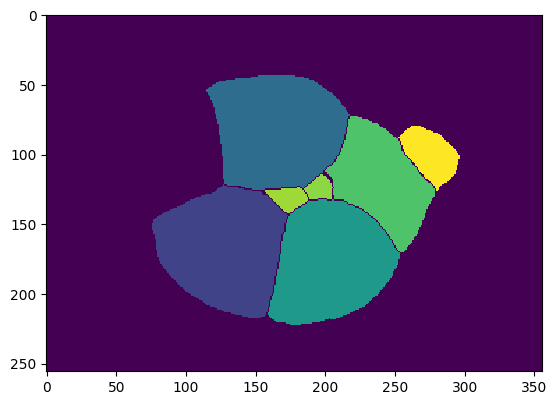

The middle segittal view (yz panel)


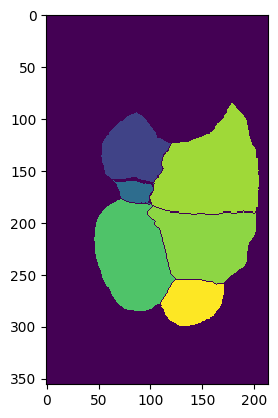

The middle coronal view (xz panel)


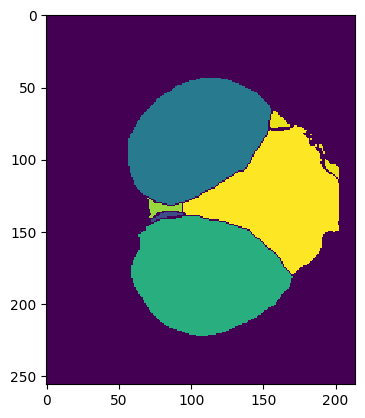

In [18]:
%%cellatlas
showing_data=nib_load(r'./dataset/run/200109plc1p1/SegCell/200109plc1p1_010_segCell.nii.gz')

print('The middle horizontal view (xy panel)')
plt.imshow(showing_data[:,:,out_size[2]//2], interpolation='nearest')
plt.show()

print('The middle segittal view (yz panel)')
plt.imshow(showing_data[out_size[0]//2,:,:], interpolation='nearest')
plt.show()

print('The middle coronal view (xz panel)')
plt.imshow(showing_data[:,out_size[1]//2,:], interpolation='nearest')
plt.show()

## 3.1 Generate pseudo nuclei with m2nGAN

The initial cells are preserved in `SegCellInitial`. The generated nucleus intensity is saved in `RawNuc_m2nGAN_prediction`. One generated peak within each initial named cell supplies the final watershed marker; missing/flat signal retains the original CD point and is reported in `reports/marker_qc.json`. This is CD-conditioned reconstruction, not de novo nucleus detection or lineage inference.

In [19]:
%%cellatlas
from reference_support import run_pseudo_stage
run_pseudo_stage(embryo_names, max_times)


/content/.cellatlas-python/lib/python3.12/site-packages/SimpleITK/extra.py:476: SyntaxWarning: invalid escape sequence '\s'
  \sa itk::simple::DiscreteGaussianImageFilter for the object oriented interface
initialize network with normal
/content/CellAtlasDemo/m2ngan/inference.py:133: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` 

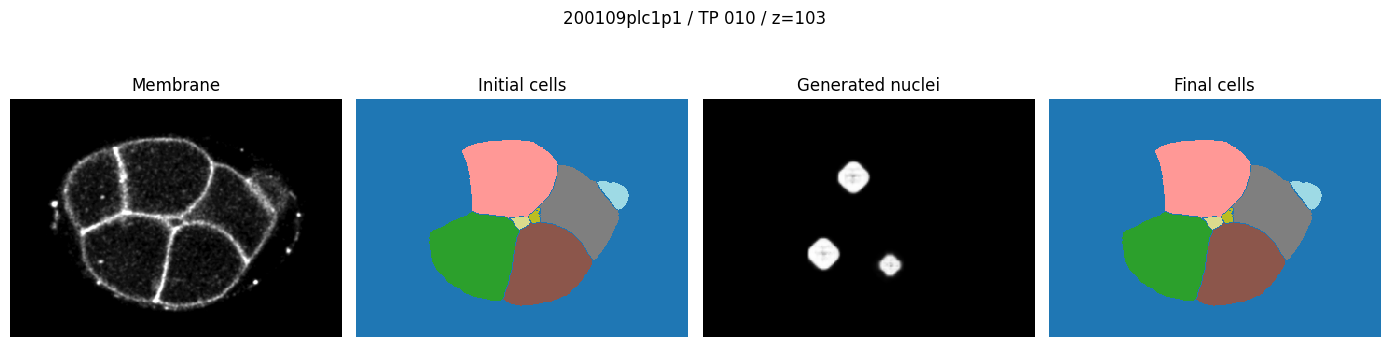

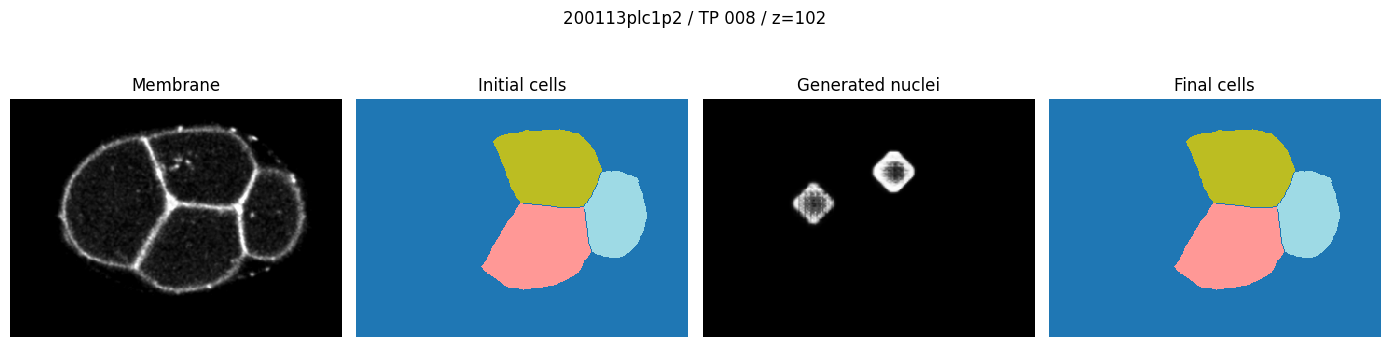

In [20]:
%%cellatlas
from reference_support import preview_pseudo_stage
preview_pseudo_stage(embryo_names, max_times)


## After we get the prespective whole-cell objects according to cell membrane segmentation results, we need to detect the dividing cell with two cell regions. So the speed may be slow while applying alpha shape generation in to dividing cells detecting (if the max time of embryo is larger than 20, high memory costing so with only 1 cpu process).

In [21]:
%%cellatlas
# Intermediate volumes remain in dataset/run; export GUI results at the end.


In [22]:
%%cellatlas
from utils.prediction_utils import combine_dividing_cells
if args.combine_dividing_cell:
    #  Combine labels by detecting the dividing cells via the cell membrane segmentation
    print("Begin combine division based on TP...\n")
    combine_dividing_cells(args)

Begin combine division based on TP...

Combining the dividing cell in SegCellDividingCells) 200109plc1p1: 100%|██████████| 10/10 [01:12<00:00,  7.22s/it]
Combining the dividing cell in SegCellDividingCells) 200113plc1p2: 100%|██████████| 8/8 [00:45<00:00,  5.69s/it]


The middle horizontal view (xy panel)


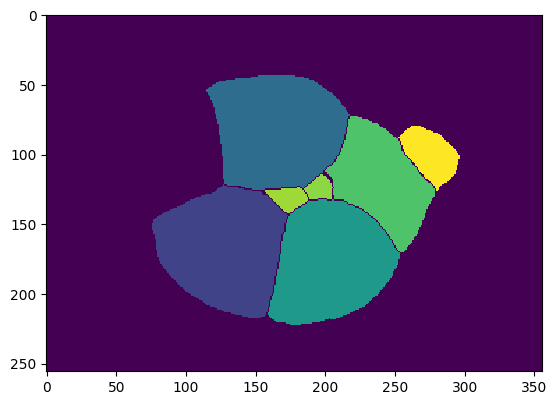

The middle segittal view (yz panel)


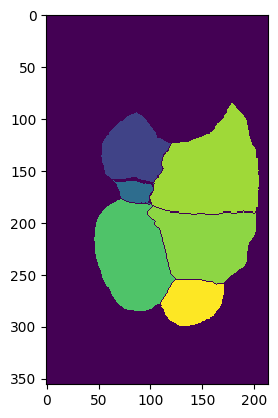

The middle coronal view (xz panel)


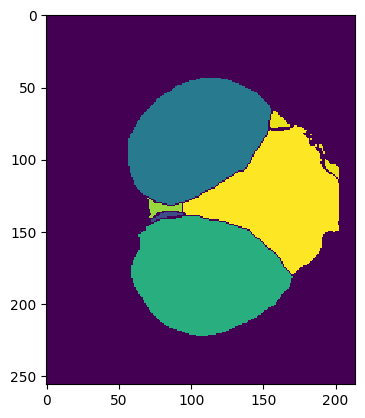

In [23]:
%%cellatlas
showing_data=nib_load(r'./dataset/run/200109plc1p1/SegCellDividingCells/200109plc1p1_010_segCell.nii.gz')

print('The middle horizontal view (xy panel)')
plt.imshow(showing_data[:,:,out_size[2]//2], interpolation='nearest')
plt.show()

print('The middle segittal view (yz panel)')
plt.imshow(showing_data[out_size[0]//2,:,:], interpolation='nearest')
plt.show()

print('The middle coronal view (xz panel)')
plt.imshow(showing_data[:,out_size[1]//2,:], interpolation='nearest')
plt.show()

# **4. Running the morphologically cell shape analysis notebook**

## After we get whole-cell objects, we should start to calculate the cell volume, cell surface and cell-cell contact surface for the further physical-biologcial-statistical analysis.

## ONLY FOR COMPLETE LINEAGE (FROM TIME POINT 1, MAX TIME IS FINE)

In [24]:
%%cellatlas
import os
import pickle
from copy import deepcopy
import nibabel as nib
import numpy as np
import pandas as pd
import open3d as o3d
import multiprocessing as mp
import matplotlib.pyplot as plt
from scipy import ndimage
from tqdm import tqdm

from utils.cell_func import get_cell_name_affine_table
from utils.general_func import load_nitf2_img
from utils.shape_model import generate_alpha_shape

In [25]:
%%cellatlas
stat_data_path=r'./middle_output'
if not os.path.exists(stat_data_path):
    os.mkdir(stat_data_path)

def calculate_cell_surface_and_contact_points(config_arg, is_debug=False):
    embryo_name = config_arg['embryo_name']
    is_calculate_cell_mesh = config_arg.get('is_calculate_cell_mesh',None)
    is_calculate_contact_file = config_arg.get('is_calculate_contact_file',None)
    showCellMesh = config_arg['showCellMesh']
    showCellContact = config_arg.get('showCellContact',None)
    time_point = config_arg['time_point']
    path_embryo = config_arg.get('path_embryo', None)

    if path_embryo is None:
        raise Exception("Sorry, no path_embryo given!")

    # ------------------------calculate surface points using dialation for each cell --------------------
    frame_this_embryo = str(time_point).zfill(3)
    file_name = embryo_name + '_' + frame_this_embryo + '_segCell.nii.gz'

    # ------------if contact file exists, finish this embryo---------------
    # contact_saving_path = os.path.join(my_config.data_cell_mesh_and_contact, 'stat', embryo_name,
    #                                    embryo_name+'_'+file_name.split('.')[0] + '_contact.txt')
    # # ===============very important line===================
    # if os.path.exists(contact_saving_path):
    #     print(contact_saving_path,' existed')
    #     return 0
    # # =====================================================

    volume = nib.load(os.path.join(path_embryo, file_name)).get_fdata().astype(int).transpose([2, 1, 0])
    if is_debug:
        print(np.unique(volume, return_counts=True))
    # this_img = load_nitf2_img()

    # volume = this_img.get_fdata().astype(int)
    # -----!!!!!!!!get cell edge boundary!!!!--------------
    cell_mask = volume != 0
    boundary_mask = (cell_mask == 0) & ndimage.binary_dilation(cell_mask)
    [x_bound, y_bound, z_bound] = np.nonzero(boundary_mask)
    boundary_elements = []

    # find boundar/points between cells
    for (x, y, z) in zip(x_bound, y_bound, z_bound):
        neighbors = volume[np.ix_(range(x - 1, x + 2), range(y - 1, y + 2), range(z - 1, z + 2))]
        neighbor_labels = list(np.unique(neighbors))
        neighbor_labels.remove(0)
        if len(neighbor_labels) == 2:  # contact between two cells
            boundary_elements.append(neighbor_labels)
    # cell contact pairs
    cell_contact_pairs = list(np.unique(np.array(boundary_elements), axis=0))
    cell_conatact_pair_renew = []
    contact_points_dict = {}
    contact_area_dict = {}

    for (label1, label2) in cell_contact_pairs:
        contact_mask = np.logical_and(ndimage.binary_dilation(volume == label1),
                                      ndimage.binary_dilation(volume == label2))
        contact_mask = np.logical_and(contact_mask, boundary_mask)
        if contact_mask.sum() > 2:

            cell_conatact_pair_renew.append((label1, label2))
            str_key = str(label1) + '_' + str(label2)
            contact_area_dict[str_key] = 0

            point_position_x, point_position_y, point_position_z = np.where(contact_mask == True)

            contact_points_list = []
            for i in range(len(point_position_x)):
                contact_points_list.append([point_position_x[i], point_position_y[i], point_position_z[i]])
            # print(str_key)
            contact_points_dict[str_key] = contact_points_list
            if is_debug:
                print('contact', str_key, len(contact_points_list))

    if is_debug:
        print('volume info', np.unique(volume, return_counts=True))
    cell_list = np.unique(volume)
    contact_mesh_dict = {}
    showing_record = []

    volume_dict = {}
    surface_dict = {}
    contact_dict = {}

    if is_debug:
        print('configuration', config_arg)
        print('cell list ', cell_list)

    # if not is_calculate_contact_file:
    #     print('loading ', contact_saving_path)
    #     with open(contact_saving_path,'rb') as handle:
    #         contact_mesh_dict = pickle.load(handle)

    # print(cell_list)
    weight_surface = 1.2031
    count_ratio_tmp = []
    for cell_key in cell_list:
        if cell_key != 0:
            cell_mask = np.logical_xor(ndimage.binary_dilation(volume == cell_key), (volume == cell_key))
            # if is_debug:
            #     print('-------',cell_key,'---------')
            #     print('surface num',(cell_mask==1).sum())
            #     print('inside sum',(volume == cell_key).sum())
            if (cell_mask == 1).sum() > 15000:
                volume_dict[cell_key] = (volume == cell_key).sum()
                surface_dict[cell_key] = cell_mask.sum() * weight_surface  # 1.2031... is derived by other papers
                irregularity = surface_dict[cell_key] ** (1 / 2) / volume_dict[cell_key] ** (1 / 3)
                if is_debug:
                    print('irregularity   ', irregularity)
                if irregularity < 2.199085:
                    print('impossible small surface', time_point, cell_key)
                for (cell1, cell2) in cell_conatact_pair_renew:
                    idx = str(cell1) + '_' + str(cell2)
                    # idx_test=
                    if cell_key not in (cell1, cell2) or idx in contact_dict.keys():
                        continue
                    # --------------------contact-----------------------------------------
                    contact_dict[idx] = len(contact_points_dict[idx]) * weight_surface
            else:
                if is_debug:
                    print(cell_key, 'surface point num', (cell_mask == 1).sum(), ' inside point num(dia)',
                          (ndimage.binary_dilation(volume == cell_key) == 1).sum())
                # ------------saving cell mesh---------------------

                tuple_tmp = np.where(ndimage.binary_dilation(volume == cell_key) == 1)
                # print(len(tuple_tmp))
                sphere_list = np.concatenate(
                    (tuple_tmp[0][:, None], tuple_tmp[1][:, None], tuple_tmp[2][:, None]), axis=1)
                adjusted_rate = 0.01
                sphere_list_adjusted = sphere_list.astype(float) + np.random.uniform(0, adjusted_rate,
                                                                                     (len(tuple_tmp[0]), 3))
                m_mesh = generate_alpha_shape(sphere_list_adjusted, displaying=showCellMesh)

                alpha_v = 1

                if not m_mesh.is_watertight():
                    for i in range(10):
                        alpha_v = alpha_v + i * 0.1
                        sphere_list_adjusted = sphere_list.astype(float) + np.random.uniform(0, adjusted_rate * (i + 1),
                                                                                             (len(tuple_tmp[0]), 3))
                        m_mesh = generate_alpha_shape(sphere_list_adjusted, alpha_value=alpha_v,
                                                      displaying=showCellMesh)
                        if is_debug:
                            print('watertight', m_mesh.is_watertight())
                            print(f"alpha={alpha_v:.3f}")
                            print('edge manifold boundary', m_mesh.is_edge_manifold(allow_boundary_edges=False))

                        if m_mesh.is_watertight():
                            break
                if is_debug:
                    print(cell_key, '=======mesh info=========', m_mesh)
                    print('edge manifold', m_mesh.is_edge_manifold(allow_boundary_edges=True))
                    print('edge manifold boundary', m_mesh.is_edge_manifold(allow_boundary_edges=False))
                    print('vertex manifold', m_mesh.is_vertex_manifold())
                    print('watertight', m_mesh.is_watertight())
                    print(f"alpha={alpha_v:.3f}")
                    print('volume====>', m_mesh.get_volume(), 'using  ', (volume == cell_key).sum())
                    print('surface area=======>', m_mesh.get_surface_area(), 'weighted ',
                          cell_mask.sum() * weight_surface)
                    # o3d.visualization.draw_geometries([m_mesh], mesh_show_back_face=True, mesh_show_wireframe=True,
                    #                                   window_name=str(cell_key))
                # -----------------can not get watertight cell anyway-----------------------------------
                if not m_mesh.is_watertight():
                    print('no watertight mesh even after 10 times generation!!!', file_name, cell_key, 'use point sum')
                    volume_dict[cell_key] = (volume == cell_key).sum()
                    surface_dict[cell_key] = cell_mask.sum() * weight_surface  # 1.154... is derived by 2/sqrt(3)
                    irregularity = (surface_dict[cell_key] ** (1 / 2) / volume_dict[cell_key] ** (1 / 3))
                    if is_debug:
                        print(irregularity)
                    if irregularity < 2.199085:
                        print('impossible small surface!!!!!!!!!!!', time_point, cell_key)
                    for (cell1, cell2) in cell_conatact_pair_renew:
                        idx = str(cell1) + '_' + str(cell2)
                        # idx_test=
                        if cell_key not in (cell1, cell2) or idx in contact_dict.keys():
                            continue
                        # --------------------contact-----------------------------------------
                        contact_dict[idx] = len(contact_points_dict[idx]) * weight_surface
                    continue
                else:  # watertight mesh
                    m_mesh = o3d.geometry.TriangleMesh(
                        o3d.utility.Vector3dVector(np.asarray(m_mesh.vertices).astype(int)), m_mesh.triangles)
                    volume_dict[cell_key] = (volume == cell_key).sum()
                    surface_dict[cell_key] = m_mesh.get_surface_area()

                    if (surface_dict[cell_key] ** (1 / 2) / volume_dict[cell_key] ** (1 / 3)) < 2.199085:
                        print('impossible small surface', time_point, cell_key)

                    # if is_debug:
                    #     o3d.visualization.draw_geometries([m_mesh], mesh_show_back_face=True,mesh_show_wireframe=True)
                    #     print()
                    # ============contact surface detection========================
                    # cell_vertices = np.asarray(m_mesh.vertices).astype(int)
                    cell_vertices = np.asarray(m_mesh.vertices)
                    # ====================contact file ============================

                    for (cell1, cell2) in cell_conatact_pair_renew:
                        idx = str(cell1) + '_' + str(cell2)
                        # idx_test=
                        if cell_key not in (cell1, cell2) or idx in contact_dict.keys():
                            continue
                        # --------------------contact-----------------------------------------
                        # print('calculating, saving or showing',path_tmp, file_name, idx, ' contact surface')

                        # build a mask to erase not contact points
                        # enumerate each points in contact surface
                        contact_mask_not = [True for i in range(len(cell_vertices))]
                        contact_vertices_loc_list = []
                        for [x, y, z] in contact_points_dict[idx]:
                            # print(x,y,z)
                            contact_vertices_loc = np.where(np.prod(cell_vertices == [x, y, z], axis=-1))
                            if len(contact_vertices_loc[0]) != 0:
                                contact_vertices_loc_list.append(contact_vertices_loc[0][0])
                                contact_mask_not[contact_vertices_loc[0][0]] = False
                        contact_mesh_dict[idx] = contact_vertices_loc_list
                        contact_mesh = deepcopy(m_mesh)
                        contact_mesh.remove_vertices_by_mask(contact_mask_not)
                        # eodo: finished: 1. check 179 embryo,2. contact sum compare with cell surface area
                        alpha_surface_area = contact_mesh.get_surface_area()
                        points_surface_area = len(contact_points_dict[idx]) * weight_surface
                        contact_dict[
                            idx] = alpha_surface_area if alpha_surface_area > points_surface_area else points_surface_area

                        if is_debug:
                            # contact_mesh = deepcopy(m_mesh)
                            # contact_mesh.remove_vertices_by_mask(contact_mask_not)
                            print(idx, '=======mesh info=========', contact_mesh)
                            print('edge manifold', contact_mesh.is_edge_manifold(allow_boundary_edges=True))
                            print('edge manifold boundary', contact_mesh.is_edge_manifold(allow_boundary_edges=False))
                            print('vertex manifold', contact_mesh.is_vertex_manifold())
                            # print('watertight', m_mesh.is_watertight())
                            print('contact surface area=======>', contact_mesh.get_surface_area(), 'while points num',
                                  points_surface_area)
                            # o3d.visualization.draw_geometries([contact_mesh], mesh_show_back_face=True,
                            #                                   mesh_show_wireframe=True)
                # -----------------CHECK IF THE SUM OF CONTACT SURFACE AREA-------------------------

                if is_debug:
                    this_cell_surface = surface_dict[cell_key]
                    contact_list_tmp = []

                    for (cell1, cell2) in cell_conatact_pair_renew:
                        idx_tmp = str(cell1) + '_' + str(cell2)
                        # idx_test=
                        if cell_key not in (cell1, cell2):
                            continue
                        contact_list_tmp.append(contact_dict[idx_tmp])
                    print('contact sum', sum(contact_list_tmp), '  surface area ', this_cell_surface)
                    ratio_this_cell = sum(contact_list_tmp) / this_cell_surface
                    if ratio_this_cell > 1:
                        count_ratio_tmp.append(ratio_this_cell)
                        # print('impossible things!!!!')

    if is_debug:
        abnormal_contact_cell_ratio = len(count_ratio_tmp) / (len(cell_list) - 1)
        print('volume dict ', volume_dict)
        print('surface dict', surface_dict)
        print('contact dict', contact_dict)
        print('-------------abnormal contact cell ratio!!!!====>  ', abnormal_contact_cell_ratio)
    # ------------saving volume surface and contact file for an embryo------------
    else:
        path_tmp = os.path.join(stat_data_path, embryo_name)
        if not os.path.exists(path_tmp):
            os.mkdir(path_tmp)
        with open(os.path.join(path_tmp, file_name.split('.')[0] + '_volume.txt'), 'wb+') as handle:
            pickle.dump(volume_dict, handle, protocol=4)
        with open(os.path.join(path_tmp, file_name.split('.')[0] + '_surface.txt'), 'wb+') as handle:
            pickle.dump(surface_dict, handle, protocol=4)
        with open(os.path.join(path_tmp, file_name.split('.')[0] + '_contact.txt'), 'wb+') as handle:
            pickle.dump(contact_dict, handle, protocol=4)

    # -------------------------------------------------------------------------------------------------------


## Calculate volume, surface and contact area sequentially in this kernel.

In [26]:
%%cellatlas
# CHANGE YOUR EMBRYO NAMES AND MAX TIMES HERE WHEN YOU ARE RUNNING ON YOUR OWN PROGRAM
max_times = [10, 8]
embryo_names = ['200109plc1p1', '200113plc1p2']


for idx, embryo_name in enumerate(embryo_names):
    configs = []
    config_tmp = {}
    config_tmp["embryo_name"] = embryo_name
    config_tmp['is_calculate_cell_mesh'] = True
    config_tmp['is_calculate_contact_file'] = True
    config_tmp['showCellMesh'] = False
    config_tmp['showCellContact'] = False
    config_tmp['path_embryo'] =os.path.join(r'./dataset/run', embryo_name, 'SegCellDividingCells')
    for tp in tqdm(range(1, max_times[idx] + 1), desc="Compose configs"):
        config_tmp['time_point'] = tp
        configs.append(config_tmp.copy())
    for idx_, _ in enumerate(
            tqdm(map(calculate_cell_surface_and_contact_points, configs), total=max_times[idx],
                 desc="calculating {} segmentations (contact, surface, volume)".format(embryo_name))):
        #
        pass

Compose configs: 100%|██████████| 10/10 [00:00<00:00, 85773.09it/s]
calculating 200109plc1p1 segmentations (contact, surface, volume):  90%|█████████ | 9/10 [03:13<00:25, 25.56s/it]CellAtlas cell is still running...
calculating 200109plc1p1 segmentations (contact, surface, volume): 100%|██████████| 10/10 [04:07<00:00, 24.70s/it]
Compose configs: 100%|██████████| 8/8 [00:00<00:00, 74400.07it/s]
calculating 200113plc1p2 segmentations (contact, surface, volume): 100%|██████████| 8/8 [01:35<00:00, 11.99s/it]


## After a long time generating morphological features, we need to generate them as well as the cell position according to the x y z resolutions, raw image sizes and CD file location.

In [27]:
%%cellatlas
import io

from utils.data_structure import construct_celltree

max_times = [10, 8]
embryo_names = ['200109plc1p1', '200113plc1p2']


tem_dir_nucloc=os.path.join(stat_data_path,'NucLocFile')
if not os.path.exists(tem_dir_nucloc):
    os.mkdir(tem_dir_nucloc)

print(embryo_names, max_times)
number_dictionary_path = os.path.join('./dataset', 'name_dictionary.csv')
pd_name_dict = pd.read_csv(number_dictionary_path, index_col=0, header=0)
label_name = pd_name_dict.to_dict()['0']
name_label = pd.Series(pd_name_dict.index, index=pd_name_dict['0']).to_dict()

# ----really important, ({raw image x}/{3D volume x}*{xy_resolution})-----------
volume_coefficient = ((512 / 256) * 0.09) ** 3
surface_coefficient = ((512 / 256) * 0.09) ** 2

for idx, embryo_name in enumerate(embryo_names):
    # ---------------------read cd file---------------------------------
    cd_file_path = os.path.join('./dataset/run/CDFiles','CD{}.csv'.format(embryo_name))
    cd_file_all_dict = {}
    with io.open(cd_file_path, mode="r", encoding="utf-8") as f:
        # next(f)
        next(f)
        for line in f:
            info_list = line.split(',')
            [cellname_, tp_] = info_list[0].split(':')
            cd_file_all_dict[(cellname_, tp_)] = info_list[1:]
    print('constructing cell tree for ', embryo_name)
    cell_tree,_=construct_celltree(cd_file_path,max_time=max_times[idx])
    # ---------------------------------------------------------------
    for tp in tqdm(range(1, max_times[idx] + 1), desc='generating {} nucloc file'.format(embryo_name)):
        cd_dict_this = {}
        no_repeat_record_list=[]
        for (cell_name_tem, tp_tem), values_tem in cd_file_all_dict.items():
            # print(type(tp_tem),type(tp))
            if str(tp) == tp_tem:
                cd_dict_this[cell_name_tem] = values_tem

        path_tmp = os.path.join(stat_data_path,embryo_name)
        # read the cell volume pkl file
        with open(os.path.join(path_tmp, '{}_{}_segCell_volume.txt'.format(embryo_name, str(tp).zfill(3))),
                  'rb') as handle:
            volume_dict = pickle.load(handle)
        # read the cell surface area pkl file
        with open(os.path.join(path_tmp, '{}_{}_segCell_surface.txt'.format(embryo_name, str(tp).zfill(3))),
                  'rb') as handle:
            surface_dict = pickle.load(handle)
        # x y z is the size of the 3D volume, designed by you
        df_nucLoc = pd.DataFrame(
            columns=['nucleus_label','nucleus_name','x_256','y_356','z_214','volume','surface','note'])
        for cell_name_, zxy_pos in cd_dict_this.items():
            cell_label_ = name_label[cell_name_]
#             print(zxy_pos)
            if cell_label_ in volume_dict.keys():
                y = int(float(zxy_pos[8]) / 712 * 356)# labelled as X in cd file
                x = int(float(zxy_pos[9]) / 512 * 256)# labelled as Y in cd file
                z = 214 - int(float(zxy_pos[7]) / 92 * 214)

                df_nucLoc.loc[len(df_nucLoc.index)] = [cell_label_, cell_name_, x, y, z,
                                                       volume_dict[cell_label_]*volume_coefficient, surface_dict[cell_label_]*surface_coefficient, None]
                continue
            # -------------deal with dividing or lost cellsssssssssssssss----------------------------
            cell_mother_node = cell_tree.parent(cell_name_)
            cell_mother_name_=cell_mother_node.tag
            cell_mother_label_ = name_label.get(cell_mother_name_, None)
            if cell_mother_label_ in volume_dict.keys() and cell_mother_label_ not in no_repeat_record_list:
                no_repeat_record_list.append(cell_mother_label_)

                children_list=cell_tree.children(cell_mother_name_)
                daughter_cell1=children_list[0].tag
                daughter_cell2=children_list[1].tag
#                 print('dividing ', embryo_name, tp, cell_mother_name_,daughter_cell1,daughter_cell2)

                cell_label1=name_label[daughter_cell1]
                cell_label2=name_label[daughter_cell2]

                zxy_pos1 = cd_dict_this[daughter_cell1]
                zxy_pos2 = cd_dict_this[daughter_cell2]

#                 print(zxy_pos1,zxy_pos2)

                y1 = int(float(zxy_pos1[8]) / 712 * 356)# labelled as X in cd file
                x1 = int(float(zxy_pos1[9]) / 512 * 256)# labelled as Y in cd file
                z1 = 214 - int(float(zxy_pos1[7]) / 92 * 214)

                y2 = int(float(zxy_pos2[8]) / 712 * 356)# labelled as X in cd file
                x2 = int(float(zxy_pos2[9]) / 512 * 256)# labelled as Y in cd file
                z2 = 214 - int(float(zxy_pos2[7]) / 92 * 214)

                df_nucLoc.loc[len(df_nucLoc.index)] = [cell_mother_label_, cell_mother_name_, None, None, None,
                                                       volume_dict[cell_mother_label_]*volume_coefficient,
                                                       surface_dict[cell_mother_label_]*surface_coefficient, 'mother']
                df_nucLoc.loc[len(df_nucLoc.index)] = [cell_label1, daughter_cell1, x1,y1, z1,None,None,
                                                       'child of {}'.format(cell_mother_name_)]
                df_nucLoc.loc[len(df_nucLoc.index)] = [cell_label2, daughter_cell2, x2,y2, z2,None,None,
                                                       'child of {}'.format(cell_mother_name_)]
            elif cell_mother_label_ not in no_repeat_record_list:
                print('lost cell ', embryo_name, tp,cell_name_)
                y = int(float(zxy_pos[8]) / 712 * 356)  # labelled as X in cd file
                x = int(float(zxy_pos[9]) / 512 * 256)  # labelled as Y in cd file
                z = 214 - int(float(zxy_pos[7]) / 92 * 214)

                df_nucLoc.loc[len(df_nucLoc.index)] = [cell_label_, cell_name_, x, y, z,
                                                       None, None, 'lost']
        tem_dir_nucloc=os.path.join(stat_data_path,'NucLocFile',embryo_name)
        if not os.path.exists(tem_dir_nucloc):
            os.mkdir(tem_dir_nucloc)
        nucLoc_save_file_path = os.path.join(stat_data_path, 'NucLocFile', embryo_name,
                                             '{}_{}_nucLoc.csv'.format(embryo_name,
                                                                       str(tp).zfill(3)))
        df_nucLoc.to_csv(nucLoc_save_file_path, index=False)

['200109plc1p1', '200113plc1p2'] [10, 8]
constructing cell tree for  200109plc1p1
generating 200109plc1p1 nucloc file:   0%|          | 0/10 [00:00<?, ?it/s]/tmp/ipykernel_1362/1200446773.py:99: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_nucLoc.loc[len(df_nucLoc.index)] = [cell_label1, daughter_cell1, x1,y1, z1,None,None,
/tmp/ipykernel_1362/1200446773.py:101: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_nucLoc.loc[len(df_nucLoc.index)] = [cell_label2, daughter_cell2, x2,y2, z2,None,No

## Now we get the nucleus location files, we can assemble all the statistical data at different time point in one csv file for generating visulized GUI Data.

In [28]:
%%cellatlas
from treelib import Tree

tem_dir_stat=os.path.join(stat_data_path,'statistics')
if not os.path.exists(tem_dir_stat):
    os.mkdir(tem_dir_stat)

# MODIFY YOUR RESOLUTION HERE FOR YOUR IMAGE!
vol_coefficient = ((512 / 256) * 0.09) ** 3
sur_coefficient = ((512 / 256) * 0.09) ** 2

# remember to adjust your parameters here, and create the dirtectory ./middle_output/statistics/{embryo name}

for idx, embryo_name in enumerate(embryo_names):
    cd_file_path = os.path.join('dataset/run/CDFiles', 'CD{}.csv'.format(embryo_name))
    cell_tree, max_time = construct_celltree(cd_file_path, max_times[idx])

    # ------------surface-------------and-----------volume-----------------------
    all_names = [cname for cname in cell_tree.expand_tree(mode=Tree.WIDTH)]
    # for idx, cell_name in enumerate(all_names):
    volume_embryo = pd.DataFrame(
        np.full(shape=(max_time, len(all_names)), fill_value=np.nan, dtype=np.float32),
        index=range(1, max_time + 1), columns=all_names)

    surface_embryo = pd.DataFrame(
        np.full(shape=(max_time, len(all_names)), fill_value=np.nan, dtype=np.float32),
        index=range(1, max_time + 1), columns=all_names)

    for tp in tqdm(range(1, max_time + 1),
                   desc='assembling volume and surface area of {} result'.format(embryo_name)):
        path_tmp = os.path.join(stat_data_path, embryo_name)
        with open(os.path.join(path_tmp, '{}_{}_segCell_volume.txt'.format(embryo_name, str(tp).zfill(3))),
                  'rb') as handle:
            volume_dict = pickle.load(handle)
        with open(os.path.join(path_tmp, '{}_{}_segCell_surface.txt'.format(embryo_name, str(tp).zfill(3))),
                  'rb') as handle:
            surface_dict = pickle.load(handle)

        for cell_label_, vol_value in volume_dict.items():
            cell_name_ = label_name[cell_label_]
            volume_embryo.loc[tp, cell_name_] = vol_value * vol_coefficient

        for cell_label_, sur_value in surface_dict.items():
            cell_name_ = label_name[cell_label_]
            surface_embryo.loc[tp, cell_name_] = sur_value * sur_coefficient

    tem_dir_stat=os.path.join(stat_data_path, 'statistics', embryo_name)
    if not os.path.exists(tem_dir_stat):
        os.mkdir(tem_dir_stat)
    volume_embryo = volume_embryo.loc[:, ((volume_embryo != 0) & (~np.isnan(volume_embryo))).any(axis=0)]
    volume_embryo.to_csv(os.path.join(stat_data_path, 'statistics', embryo_name, embryo_name + '_volume.csv'))
    surface_embryo = surface_embryo.loc[:, ((surface_embryo != 0) & (~np.isnan(surface_embryo))).any(axis=0)]
    surface_embryo.to_csv(os.path.join(stat_data_path, 'statistics', embryo_name, embryo_name + '_surface.csv'))

    # ------------contact-----------initialize the contact csv  file----------------------
    # Get tuble lists with elements from the list

    name_combination = []
    first_level_names = []
    for i, name1 in enumerate(all_names):
        for name2 in all_names[i + 1:]:
            if not (cell_tree.is_ancestor(name1, name2) or cell_tree.is_ancestor(name2, name1)):
                first_level_names.append(name1)
                name_combination.append((name1, name2))

    multi_index = pd.MultiIndex.from_tuples(name_combination, names=['cell1', 'cell2'])
    # print(multi_index)
    stat_embryo = pd.DataFrame(
        np.full(shape=(max_time, len(name_combination)), fill_value=np.nan, dtype=np.float32),
        index=range(1, max_time + 1), columns=multi_index)
    # set zero element to express the exist of the specific nucleus
    for cell_name in all_names:
        if cell_name not in first_level_names:
            continue
        try:
            cell_time = cell_tree.get_node(cell_name).data.get_time()
            cell_time = [x for x in cell_time if x <= max_time]
            stat_embryo.loc[cell_time, (cell_name, slice(None))] = 0
        except:
            cell_name
    # print(stat_embryo)
    # edges_view = point_embryo.edges(data=True)
    for tp in tqdm(range(1, max_times[idx] + 1),
                   desc='assembling contact surface of {} result'.format(embryo_name)):
        path_tmp = os.path.join(stat_data_path, embryo_name)
        with open(os.path.join(path_tmp, '{}_{}_segCell_contact.txt'.format(embryo_name, str(tp).zfill(3))),
                  'rb') as handle:
            contact_dict = pickle.load(handle)
        for contact_sur_idx, contact_sur_value in contact_dict.items():
            [cell1, cell2] = contact_sur_idx.split('_')
            cell1_name = label_name[int(cell1)]
            cell2_name = label_name[int(cell2)]
            if (cell1_name, cell2_name) in stat_embryo.columns:
                stat_embryo.loc[tp, (cell1_name, cell2_name)] = contact_sur_value * sur_coefficient
            elif (cell2_name, cell1_name) in stat_embryo.columns:
                stat_embryo.loc[tp, (cell2_name, cell1_name)] = contact_sur_value * sur_coefficient
            else:
                pass
                # print('columns missing (cell1_name, cell2_name)')
    stat_embryo = stat_embryo.loc[:, ((stat_embryo != 0) & (~np.isnan(stat_embryo))).any(axis=0)]
    print(stat_embryo)
    stat_embryo.to_csv(os.path.join(stat_data_path, 'statistics', embryo_name, embryo_name + '_contact.csv'))
    # --------------------------------------------------------------------------------------------

assembling volume and surface area of 200109plc1p1 result:   0%|          | 0/10 [00:00<?, ?it/s]/tmp/ipykernel_1362/3856231141.py:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '5923.719864' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  volume_embryo.loc[tp, cell_name_] = vol_value * vol_coefficient
/tmp/ipykernel_1362/3856231141.py:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '5748.4274399999995' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  volume_embryo.loc[tp, cell_name_] = vol_value * vol_coefficient
/tmp/ipykernel_1362/3856231141.py:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '4749.429168' has dtype incompatible with float32, please ex

# **5. Generate the GUIData for the visualization software ITK-CVE-SNAP, also named visualized morphological data**

In [29]:
%%cellatlas
import os
import glob
import numpy as np
import nibabel as nib
from tqdm import tqdm
import pandas as pd
from csv import reader, writer

from utils.data_io import check_folder, move_file
from utils.data_structure import construct_celltree,read_cd_file


def CTransformerAddZeroToUnresonableBlank(gui_source_data_path,gui_target_data_path,embryo_names):

    # max_times = {"200117plc1pop1ip3":155}
    for embryo_name in embryo_names:
        contact_file=pd.read_csv(os.path.join(gui_source_data_path,embryo_name,embryo_name+'_Stat.csv'),header=0,index_col=[0,1])
        # for column_num,column_value in enumerate(contact_file.columns):
        #     print(column_num,column_value)
        # print(not contact_file.at[('Dap','Daaa'),str(144)]>=0)
        # print(not contact_file.loc[('Dap','Daaa')][143]>=0)
        # # Earap
        # # Earpp
        # print(not contact_file.at[('Earap','Earpp'),str(144)]>=0)
        #
        # input()
        for tp_index in contact_file.index:
            # print(embryo_name,'  contact pairs  ',tp_index)
            start_column=0
            stop_column=0
            first_flag=False
            # notNullIndex=contact_file.loc[tp_index].notna()
            for column_num,column_value in enumerate(contact_file.columns):
                # print(notNullIndex.loc[idx])
                if contact_file.at[tp_index,column_value]>=0 and not first_flag:
                    start_column=column_num
                    first_flag=True
                if contact_file.at[tp_index,column_value]>=0:
                    stop_column=column_num

            # print(start_column,stop_column)
            for col in range(start_column,stop_column+1):
                # if tp_index == ('Dap', 'Daaa'):
                #     # print(start_column, stop_column)
                #     print(col,not contact_file.loc[tp_index].iloc[col]>=0)
                # if contact_file.loc[tp_index].iloc[col]<0:
                #     print('gagagaga')
                if not contact_file.loc[tp_index].iloc[col] >=0:
                    # print(tp_index,col)
                    contact_file.loc[tp_index].iloc[col]=0
            # print(notNullIndex)
        contact_file.to_csv(os.path.join(gui_target_data_path,embryo_name,embryo_name+'_Stat.csv'))

def transpose_csv(source_file, target_file):
    with open(source_file) as f, open(target_file, 'w', newline='') as fw:
        writer(fw, delimiter=',').writerows(zip(*reader(f, delimiter=',')))

In [30]:
%%cellatlas
TP_CELLS_FLAGE = True
CELLSPAN_FLAG = True
NEIGHBOR_FLAG = True
GET_DIVISIONS = True
COPY_FILE_SEGMENTED = True
COPY_STAT_FILE=True

# ==============================================================================
# basic information of your data, keep consistent with the previous 4 steps
# ==============================================================================

stat_data_path=r'./middle_output/statistics'
embryo_data_source=r'./dataset/run'
max_times = [10, 8]
embryo_names = ['200109plc1p1', '200113plc1p2']

# ==============================================================================
# generate data for GUI
# ==============================================================================

save_folder = r'./GUIDataCellWise'

name_dictionary_path = os.path.join('./dataset', 'name_dictionary.csv')
pd_name_dict = pd.read_csv(name_dictionary_path, index_col=0, header=0)
label_name_dict = pd_name_dict.to_dict()['0']
name_label_dict = pd.Series(pd_name_dict.index, index=pd_name_dict['0']).to_dict()

all_lost_cells = []


## Let's generate the cell-wise gui data, which could be open in the ITK-CVE-SNAP, a very powerful software for your biological oberservation.



In [31]:
%%cellatlas
# ================== copy files ==============================
if COPY_STAT_FILE:
    # volume
    for embryo_name in tqdm(embryo_names, desc="Moving stat files from segmented cellular embryos"):
        check_folder(os.path.join(save_folder, embryo_name))
        move_file(os.path.join(stat_data_path, embryo_name, embryo_name + "_surface.csv"),
                        os.path.join(save_folder, embryo_name, embryo_name + "_surface.csv"))

        move_file(os.path.join(stat_data_path, embryo_name, embryo_name + "_volume.csv"),
                        os.path.join(save_folder, embryo_name, embryo_name + "_volume.csv"))
        # contact (with transpose)
        transpose_csv(os.path.join(stat_data_path, embryo_name, embryo_name + "_contact.csv"),
                      os.path.join(save_folder, embryo_name, embryo_name + "_Stat.csv"))
        if COPY_FILE_SEGMENTED:
            raw_folder0 = os.path.join(embryo_data_source, embryo_name, "RawMemb")
            raw_files = sorted(glob.glob(os.path.join(raw_folder0, "*.nii.gz")))
            seg_folder0 = os.path.join(embryo_data_source, embryo_name, "SegCellDividingCells")
            seg_files = sorted(glob.glob(os.path.join(seg_folder0, "*.nii.gz")))

            # create the folder structure automatically
            save_file = os.path.join(save_folder, embryo_name, "SegCell", os.path.basename(raw_files[0]))
            check_folder(save_file)
            save_file = os.path.join(save_folder, embryo_name, "RawMemb", os.path.basename(raw_files[0]))
            check_folder(save_file)
            for raw_file, seg_file in zip(raw_files, seg_files):
                save_file = os.path.join(save_folder, embryo_name, "RawMemb", os.path.basename(raw_file))
                move_file(raw_file, save_file)
                save_file = os.path.join(save_folder, embryo_name, "SegCell", os.path.basename(seg_file))
                move_file(seg_file, save_file)

    move_file(name_dictionary_path, save_folder + "/name_dictionary.csv")

    CTransformerAddZeroToUnresonableBlank(save_folder,save_folder,embryo_names)


Moving stat files from segmented cellular embryos: 100%|██████████| 2/2 [00:00<00:00,  6.76it/s]
/tmp/ipykernel_1362/129077059.py:50: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  contact_file.loc[tp_index].iloc[col]=0


In [32]:
%%cellatlas
# =================== save cell life span and other things ======================================

print('--------------------------------------------------------------------')
for idx,embryo_name in enumerate(embryo_names):
    print("Processing {} \n".format(embryo_name))

    volume_file = os.path.join(stat_data_path, embryo_name, embryo_name + "_volume.csv")
    contact_file = os.path.join(stat_data_path, embryo_name, embryo_name + "_contact.csv")
    volume_pd = pd.read_csv(volume_file, header=0, index_col=0)
    volume_pd.index = list(range(1, len(volume_pd.index) + 1, 1)) # todo:what is this?useless?
    contact_pd = pd.read_csv(contact_file, header=[0, 1], index_col=0)

    # ------------------------cd file nucleus----------------------------------
    cd_file_path = os.path.join(embryo_data_source,'CDFiles', 'CD{}.csv'.format(embryo_name))
    ace_pd = read_cd_file(cd_file_path)
    cell_tree, max_time = construct_celltree(cd_file_path, max_times[idx])

    # ----------------save cells at TPCell folder
    if TP_CELLS_FLAGE:
        bar = tqdm(total=len(volume_pd))
        bar.set_description("saving tp cells")
        for tp, row in volume_pd.iterrows():
            row = row.dropna()
            cell_names = list(row.index)
            cell_label = [name_label_dict[x] for x in cell_names] # transfer the cell name to cell label

            write_file = os.path.join(save_folder, embryo_name, "TPCell", "{}_{}_cells.txt".format(embryo_name, str(tp).zfill(3)))
            write_string = ",".join([str(x) for x in cell_label]) + "\n" # save the cell label for this tp
            check_folder(write_file)

            with open(write_file, "w") as f:
                f.write(write_string)
            bar.update(1)


    # save ****_lifecycle.csv
    if CELLSPAN_FLAG:
        write_file = os.path.join(save_folder, embryo_name, "{}_lifescycle.csv".format(embryo_name))
        check_folder(write_file)

        open(write_file, "w").close()
        bar = tqdm(total=len(volume_pd.columns)) # go through volume csv
        bar.set_description("saving life cycle")
        for cell_col in volume_pd: # go through volume csv (cell name)
            valid_index = volume_pd[cell_col].notnull()
            tps = list(volume_pd[valid_index].index) # get the existing time point of this cell
            label_tps = [name_label_dict[cell_col]] + tps # combine the cell label and the existing time as a list

            write_string = ",".join([str(x) for x in label_tps]) + "\n"

            with open(write_file, "a") as f:
                f.write(write_string)

        bar.update(1)

    # save neighbors ---GuiNeighbor
    if NEIGHBOR_FLAG:
        contact_pd = contact_pd.replace(0, np.nan)
        bar = tqdm(total=len(contact_pd))
        bar.set_description("saving neighbors")
        for tp, row in contact_pd.iterrows():
            row = row.dropna()
            neighbors = {}
            pairs = sorted(list(row.index))
            if len(pairs) == 0:
                continue
            for cell1, cell2 in pairs:
                cell1 = name_label_dict[cell1]
                cell2 = name_label_dict[cell2]
                if cell1 not in neighbors:
                    neighbors[cell1] = [cell2]
                else:
                    neighbors[cell1] += [cell2]

                if cell2 not in neighbors:
                    neighbors[cell2] = [cell1]
                else:
                    neighbors[cell2] += [cell1]

            write_file = os.path.join(save_folder, embryo_name, "GuiNeighbor", "{}_{}_guiNeighbor.txt".format(embryo_name, str(tp).zfill(3)))
            check_folder(write_file)

            open(write_file, "w").close()
            with open(write_file, "a") as f:

                for k, v in neighbors.items(): # cell label and its neighborhood
                    labels = [k] + list(set(v))
                    write_string = ",".join([str(x) for x in labels]) + "\n"
                    f.write(write_string)

            bar.update(1)


    # write division ------------ DivisionCell
    if GET_DIVISIONS:
        bar = tqdm(total=len(volume_pd))
        bar.set_description("saving neighbors")
        for tp, row in volume_pd.iterrows():
            row = row.dropna()
            cur_ace_pd = ace_pd[ace_pd["time"] == tp]
            nuc_cells = list(cur_ace_pd["cell"])  # cell in cd file this time point
            seg_cells = list(row.index)  # cell in volume.csv this time point
            dif_cells = list(set(nuc_cells) - set(seg_cells)) # only get the additional cells; lost cell?

            division_cells = []
            lost_cells = []

            # get average radius
            radii_mean = np.power(row, 1/3).mean()
            lost_radius = radii_mean * 1.3

            # if tp == 179:
            #     print("TEST")

            for dif_cell in dif_cells:
                parent_cell = cell_tree.parent(dif_cell).tag
                sister_cells = [x.tag for x in cell_tree.children(parent_cell)]
                sister_cells.remove(dif_cell)
                sister_cell = sister_cells[0]
                # assert parent_cell in seg_cells
                # division_cells.append(parent_cell)
                if parent_cell in seg_cells:
                    division_cells.append(parent_cell)
                else:
                    all_lost_cells.append("{}_{}_{}".format(embryo_name, dif_cell, str(tp).zfill(3)))
                    lost_cells.append(dif_cell)
            # each tp
            division_cells = list(set(division_cells))
            lost_cells = list(set(lost_cells))
            division_cells = [name_label_dict[x] for x in division_cells]
            lost_cells = [name_label_dict[x] for x in lost_cells]

            write_file = os.path.join(save_folder, embryo_name, "LostCell", "{}_{}_lostCell.txt".format(embryo_name, str(tp).zfill(3)))
            write_string = ",".join([str(x) for x in lost_cells]) + "\n"
            check_folder(write_file)

            with open(write_file, "w") as f:
                f.write(write_string)

            write_file = os.path.join(save_folder, embryo_name, "DivisionCell", "{}_{}_division.txt".format(embryo_name, str(tp).zfill(3)))
            write_string = ",".join([str(x) for x in division_cells]) + "\n"
            check_folder(write_file)

            with open(write_file, "w") as f:
                f.write(write_string)

            bar.update(1)

--------------------------------------------------------------------
Processing 200109plc1p1 

saving tp cells: 100%|██████████| 10/10 [00:00<00:00, 1293.94it/s]

saving neighbors: 100%|██████████| 10/10 [00:00<00:00, 859.19it/s]

saving neighbors:   0%|          | 0/10 [00:00<?, ?it/s]Processing 200113plc1p2 

saving tp cells: 100%|██████████| 8/8 [00:00<00:00, 546.86it/s]

saving neighbors: 100%|██████████| 8/8 [00:00<00:00, 606.49it/s]

saving neighbors:   0%|          | 0/8 [00:00<?, ?it/s]

## Cell-wise GUI data is ready locally.

Next, generate the original tissue-wise GUI data. Both directories are copied to Drive in the final export cell.

In [33]:
%%cellatlas
TP_CELLS_FLAGE = True
CELLSPAN_FLAG = True
NEIGHBOR_FLAG = True
GET_DIVISIONS = True
COPY_FILE = True
COPY_RAW=True

to_save_folder = r"./GUIDataTissueWise"
cell_wise_gui_data_folder = r'./GUIDataCellWise'



# =========================================================================
# read cell fate, we have generate all cell fate under 550-cell stage
# =========================================================================
fate_file = r'./dataset/CellFate.xls'
cell_fate = pd.read_excel(fate_file, names=["Cell", "Fate"], converters={"Cell": str, "Fate": str}, header=None)
cell_fate = cell_fate.applymap(lambda x: x[:-1])
cell2fate = dict(zip(cell_fate.Cell, cell_fate.Fate))
all_fates = sorted(list(set(sorted(list(cell_fate.Fate)))))
fate2label = dict(zip(all_fates, list(range(1, len(all_fates) + 1, 1))))

cell_fate_label_pairted_path = r'./dataset/CTransformerPairedFate.csv'
cell_fate["Cell label"] = cell_fate.apply(lambda x: name_label_dict.get(x["Cell"],None), axis=1)
cell_fate["Fate label"] = cell_fate.apply(lambda x: fate2label.get(x["Fate"],None), axis=1)
cell_fate.to_csv(cell_fate_label_pairted_path, index=False)
# =========================
# change to fate-wise labels
# =========================
def change_labels(seg, label2name_dict, cell2fate, fate2label):
    new_seg = np.zeros_like(seg)
    labels = list(np.unique(seg))[1:]
    for label in labels:
        cell_name = label2name_dict[label]
        if cell_name in cell2fate.keys():
            cell_fate=cell2fate[cell_name]
        else:
            cell_fate =  'Unspecified'
            print(cell_name,'cell name fate not exist, and set to unspecified')
        tissue_label = fate2label[cell_fate]
        new_seg[seg == label] = tissue_label

    return new_seg

/tmp/ipykernel_1362/3118232823.py:18: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  cell_fate = cell_fate.applymap(lambda x: x[:-1])


## We need to copy the statistics results for ITK-CVE-SNAP openning successfully.

In [34]:
%%cellatlas
from utils.data_io import nib_load, nib_save

if COPY_FILE:
    # volume
    for embryo_name in tqdm(embryo_names, desc="Moving files to GUI Fate-wise from GUI Cell-wise data"):

        # check and create the data folder backbone if the folder tree is not existed

        raw_folder = os.path.join(cell_wise_gui_data_folder, embryo_name, "RawMemb")
        raw_files = sorted(glob.glob(os.path.join(raw_folder, "*.nii.gz")))
        seg_folder = os.path.join(cell_wise_gui_data_folder, embryo_name, "SegCell")
        seg_files = sorted(glob.glob(os.path.join(seg_folder, "*.nii.gz")))

        save_file = os.path.join(to_save_folder, embryo_name, "SegCell", os.path.basename(seg_files[0]))
        check_folder(save_file)
        save_file = os.path.join(to_save_folder, embryo_name, "RawMemb", os.path.basename(raw_files[0]))
        check_folder(save_file)

        # ----------copy surface file-----------------
        file_name = os.path.join(cell_wise_gui_data_folder, embryo_name, embryo_name + "_surface.csv")
        pd_data = pd.read_csv(file_name, index_col=0, header=0)
        pd_data = pd_data.applymap(lambda x: "")
        file_name = os.path.join(to_save_folder, embryo_name, embryo_name + "_surface.csv")
        check_folder(file_name)
        pd_data.to_csv(file_name)

        # --------copy volume file----------------
        file_name = os.path.join(cell_wise_gui_data_folder, embryo_name, embryo_name + "_volume.csv")
        pd_data = pd.read_csv(file_name, index_col=0, header=0)
        pd_data = pd_data.applymap(lambda x: "")
        file_name = os.path.join(to_save_folder, embryo_name, embryo_name + "_volume.csv")
        pd_data.to_csv(file_name)

        # ---------copy contact are file----------
        file_name = os.path.join(to_save_folder, embryo_name, embryo_name + "_Stat.csv")
        move_file(os.path.join(cell_wise_gui_data_folder, embryo_name, embryo_name + "_Stat.csv"),file_name)
        pd_data = pd.read_csv(file_name, index_col=None, header=0)
        pd_data = pd_data.applymap(lambda x: "")
        pd_data.to_csv(file_name, index=False)


        for raw_file, seg_file in zip(raw_files, seg_files):
            save_file = os.path.join(to_save_folder, embryo_name, "SegCell", os.path.basename(seg_file))
            # change cell label flag to cell fate
            seg = nib_load(seg_file)
            seg = change_labels(seg, label_name_dict, cell2fate, fate2label)
            nib_save(seg, save_file)
            if COPY_RAW:
                save_file = os.path.join(to_save_folder, embryo_name, "RawMemb", os.path.basename(raw_file))
                move_file(raw_file, save_file)

move_file('./dataset/tissue_wise_name_dictionary.csv', to_save_folder + "/name_dictionary.csv")

Moving files to GUI Fate-wise from GUI Cell-wise data:   0%|          | 0/2 [00:00<?, ?it/s]/tmp/ipykernel_1362/807796777.py:22: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  pd_data = pd_data.applymap(lambda x: "")
/tmp/ipykernel_1362/807796777.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  pd_data = pd_data.applymap(lambda x: "")
/tmp/ipykernel_1362/807796777.py:38: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  pd_data = pd_data.applymap(lambda x: "")
CellAtlas cell is still running...
Moving files to GUI Fate-wise from GUI Cell-wise data:  50%|█████     | 1/2 [00:32<00:32, 32.54s/it]/tmp/ipykernel_1362/807796777.py:22: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  pd_data = pd_data.applymap(lambda x: "")
/tmp/ipykernel_1362/807796777.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  pd_d

## generate other nececessary things for Tissue-wise gui data

In [35]:
%%cellatlas
# ============================deal with calculation things===================================
for idx,embryo_name in enumerate(embryo_names):
    print("Processing {} \n".format(embryo_name))

    seg_folder = os.path.join(to_save_folder, embryo_name, "SegCell")
    seg_files = sorted(glob.glob(os.path.join(seg_folder, "*.nii.gz")))

    volume_file = os.path.join(cell_wise_gui_data_folder, embryo_name, "{}_volume.csv".format(embryo_name))
    ace_file = os.path.join(embryo_data_source, 'CDFiles', "CD{}.csv".format(embryo_name))

    volume_pd = pd.read_csv(volume_file, header=0, index_col=0)
    volume_pd.index = list(range(1, len(volume_pd.index) + 1, 1))
    celltree, _ = construct_celltree(ace_file, max_time=max_times[idx])

    # save cells at tp
    if TP_CELLS_FLAGE:
        # =================== save cell life span ======================================
        bar = tqdm(total=len(seg_files))
        bar.set_description("saving tp cells")
        for tp in range(1, len(seg_files)+1, 1):

            write_file = os.path.join(to_save_folder, embryo_name, "TPCell", "{}_{}_cells.txt".format(embryo_name, str(tp).zfill(3)))
            cell_label =list(fate2label.values())
            write_string = ",".join([str(x) for x in cell_label]) + "\n"
            check_folder(write_file)

            with open(write_file, "w") as f:
                f.write(write_string)
            bar.update(1)


        # save lifecycle.csv
    if CELLSPAN_FLAG:
        write_file = os.path.join(to_save_folder, embryo_name, "{}_lifescycle.csv".format(embryo_name))
        check_folder(write_file)

        open(write_file, "w").close()
        bar = tqdm(total=len(volume_pd.columns))
        bar.set_description("saving life cycle")
        for cell_col in list(fate2label.values()):
            label_tps = [str(cell_col)] + list(range(1, len(volume_pd.index)+1, 1))

            write_string = ",".join([str(x) for x in label_tps]) + "\n"

            with open(write_file, "a") as f:
                f.write(write_string)

        bar.update(1)

    # save neighbors
    if NEIGHBOR_FLAG:
        bar = tqdm(total=len(seg_files))
        bar.set_description("saving neighbors")
        for tp in range(1, len(seg_files)+1, 1):

            write_file = os.path.join(to_save_folder, embryo_name, "GuiNeighbor", "{}_{}_guiNeighbor.txt".format(embryo_name, str(tp).zfill(3)))
            check_folder(write_file)

            neighbors = {1: [2], 2:[1]}
            with open(write_file, "a") as f:

                for k, v in neighbors.items():
                    labels = [k] + list(set(v))
                    write_string = ",".join([str(x) for x in labels]) + "\n"
                    f.write(write_string)

            bar.update(1)

    # write division
    if GET_DIVISIONS:
        bar = tqdm(total=len(volume_pd))
        bar.set_description("saving divisions")
        for tp, row in volume_pd.iterrows():


            write_file = os.path.join(to_save_folder, embryo_name, "LostCell", "{}_{}_lostCell.txt".format(embryo_name, str(tp).zfill(3)))
            write_string = "\n"
            check_folder(write_file)

            with open(write_file, "w") as f:
                f.write(write_string)

            write_file = os.path.join(to_save_folder, embryo_name, "DivisionCell", "{}_{}_division.txt".format(embryo_name, str(tp).zfill(3)))
            write_string = "\n"
            check_folder(write_file)

            with open(write_file, "w") as f:
                f.write(write_string)

            bar.update(1)


Processing 200109plc1p1 

saving tp cells: 100%|██████████| 10/10 [00:00<00:00, 540.91it/s]

saving neighbors: 100%|██████████| 10/10 [00:00<00:00, 702.76it/s]

saving divisions:   0%|          | 0/10 [00:00<?, ?it/s]Processing 200113plc1p2 

saving tp cells: 100%|██████████| 8/8 [00:00<00:00, 613.30it/s]

saving neighbors: 100%|██████████| 8/8 [00:00<00:00, 684.41it/s]

saving divisions:   0%|          | 0/8 [00:00<?, ?it/s]

## Both GUI directories are ready locally.

Run the final checks and export below, then open the exported folders with ITK-CVE-SNAP.

## Check and save the results

In [36]:
%%cellatlas
from reference_support import final_qc
final_qc(embryo_names, max_times)


CellAtlas cell is still running...
Full pipeline output checks passed: 18 frames.


In [37]:
from pathlib import Path
import shutil
destination = Path("/content/drive/MyDrive/CellAtlasDemoResults")
if destination.exists():
    raise FileExistsError("Rename the previous CellAtlasDemoResults folder before exporting this run.")
destination.mkdir()
for name in ["GUIDataCellWise", "GUIDataTissueWise", "middle_output", "reports"]:
    shutil.copytree(ROOT / name, destination / name)
for record in json.loads((ROOT / "reports/tiff_qc.json").read_text()):
    embryo = record["embryo"]
    for name in ["RawNuc_m2nGAN_prediction", "SegNucGenerated", "SegNucCD"]:
        shutil.copytree(ROOT / "dataset/run" / embryo / name,
                        destination / "GeneratedNuclei" / embryo / name)
print("Results saved to:", destination)


Results saved to: /content/drive/MyDrive/CellAtlasDemoResults
